# Movie Genre Classification — Notebook 1: EDA
**MSDS 565 • Team3 • CRISP-DM: Business Understanding and Data Understanding**

**Goal.** Understand the supplied movie table, select a modest vote filter and explore genre and text patterns. This notebook contains no feature vectorization or model fitting.

**Controlling instructions.** The separately supplied **P3_Prompt (1).pdf** requires three notebooks. The five-notebook `Project/P3_Prompt.md` inside the course ZIP is an older, conflicting assignment and is not used.

Every numbered section follows **Decision → Explanation → Code → Interpretation**. Values under “Observed interpretation” are computed from the actual run.

### Setup
Use the existing `Python (msds565)` kernel after installing the dependencies listed in the README. Keep `mpst_imdb_movies.csv` in the sibling `MovieGenre_work` folder. Missing metadata values remain missing in EDA; no metadata is used as a model input later.

In [2]:
from pathlib import Path
import os, re, json, hashlib, pickle, warnings, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

SEED = 42
TEAM = 'Team3'
MIN_VOTES = 100
GENRES = ['Comedy', 'Horror', 'Action']
here = Path.cwd().resolve()
ROOT = here.parent if here.name == 'notebooks' else here
assert ROOT.name == f'MSDS565-MovieGenre-{TEAM}', 'Open the notebook from the extracted project folder.'
# Data, generated CSVs and caches stay OUTSIDE the GitHub repository.
WORK = Path(os.environ.get('P3_WORK_DIR', ROOT.parent / 'MovieGenre_work')).expanduser().resolve()
WORK.mkdir(parents=True, exist_ok=True)
CACHE = WORK / 'cache'
CACHE.mkdir(exist_ok=True)
DATA = Path(os.environ.get('P3_DATA_PATH', WORK / 'mpst_imdb_movies.csv')).expanduser().resolve()
MODELS = ROOT / 'models'
MODELS.mkdir(exist_ok=True)
assert ROOT not in WORK.parents and WORK != ROOT, 'P3_WORK_DIR must be outside the repository.'
assert ROOT not in DATA.parents, 'Keep the supplied CSV outside the repository.'
assert DATA.is_file(), 'Place mpst_imdb_movies.csv in ../MovieGenre_work/ or set P3_DATA_PATH.'
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
BLUE, ORANGE = '#28618C', '#BD6A28'

def note(text): display(Markdown('**Observed interpretation.** ' + text))
def normalized_text(series): return series.str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
def read_movies():
    frame = pd.read_csv(DATA)
    required = ['imdb_id','primaryTitle','plot_synopsis','split','numVotes',*GENRES]
    assert set(required).issubset(frame.columns)
    assert not frame.imdb_id.duplicated().any(), 'One row per imdb_id is required.'
    assert not frame[required].isna().any().any()
    assert frame.split.isin(['train','val','test']).all()
    assert frame.plot_synopsis.str.strip().str.len().gt(0).all()
    frame = frame.loc[frame.numVotes >= MIN_VOTES].copy().reset_index(drop=True)
    assert frame[GENRES].isin([0,1]).all().all()
    return frame

def frame_fingerprint(frame):
    # Labels, order, split and text are all part of the handoff identity.
    cols = ['imdb_id','plot_synopsis','split','numVotes',*GENRES]
    return hashlib.sha256(pd.util.hash_pandas_object(frame[cols], index=False).values.tobytes()).hexdigest()

print(f'Team: {TEAM}; minimum votes: {MIN_VOTES}; data: {DATA.name}')

Team: Team3; minimum votes: 100; data: mpst_imdb_movies.csv


## 1. Movie characteristics

**Decision.** Use the supplied joined CSV and retain movies with at least 100 votes.

**Explanation.** A small vote floor removes minimally rated films without aggressively restricting the corpus to popular titles. Compare several thresholds for transparency, then fix 100 for all notebooks. Preserve the provided split and unique movie IDs.

In [3]:
raw = pd.read_csv(DATA)
genre_columns = [c for c in raw.columns if c not in [
    'imdb_id','primaryTitle','plot_synopsis','synopsis_source','split',
    'startYear','runtimeMinutes','averageRating','numVotes']]
assert raw[genre_columns].isin([0,1]).all().all()
display(pd.DataFrame({'rows':[len(raw)],'unique_movies':[raw.imdb_id.nunique()],
                      'missing_year':[raw.startYear.isna().sum()],
                      'missing_runtime':[raw.runtimeMinutes.isna().sum()]}))
thresholds = pd.DataFrame({v:raw.assign(keep=raw.numVotes.ge(v)).groupby('split').keep.sum()
                           for v in [0,100,500,1000]}).rename_axis('split')
thresholds.columns = [f'kept_at_{v}_votes' for v in thresholds.columns]
display(thresholds)
df = read_movies()
before = raw.groupby('split').size().reindex(['train','val','test'])
after = df.groupby('split').size().reindex(before.index,fill_value=0)
filter_audit = pd.DataFrame({'before':before,'retained':after,'dropped':before-after})
filter_audit['dropped_pct'] = 100*filter_audit.dropped/filter_audit.before
display(filter_audit.round(2))
filter_audit.to_csv(WORK/'vote_filter_audit.csv')
note(f'The {MIN_VOTES}-vote floor retains {len(df):,} of {len(raw):,} movies '
     f'and removes {len(raw)-len(df):,} ({(len(raw)-len(df))/len(raw):.2%}). '
     f'There are {raw.startYear.isna().sum()} missing release years and '
     f'{raw.runtimeMinutes.isna().sum()} missing runtimes before filtering; those values are omitted only from the corresponding plots.')

,rows,unique_movies,missing_year,missing_runtime
0,11824,11824,1,7


,kept_at_0_votes,kept_at_100_votes,kept_at_500_votes,kept_at_1000_votes
split,,,,
test,2360,2330,2209,2075
train,7596,7517,7122,6647
val,1868,1848,1758,1663


,before,retained,dropped,dropped_pct
split,,,,
train,7596,7517,79,1.04
val,1868,1848,20,1.07
test,2360,2330,30,1.27


**Observed interpretation.** The 100-vote floor retains 11,695 of 11,824 movies and removes 129 (1.09%). There are 1 missing release years and 7 missing runtimes before filtering; those values are omitted only from the corresponding plots.

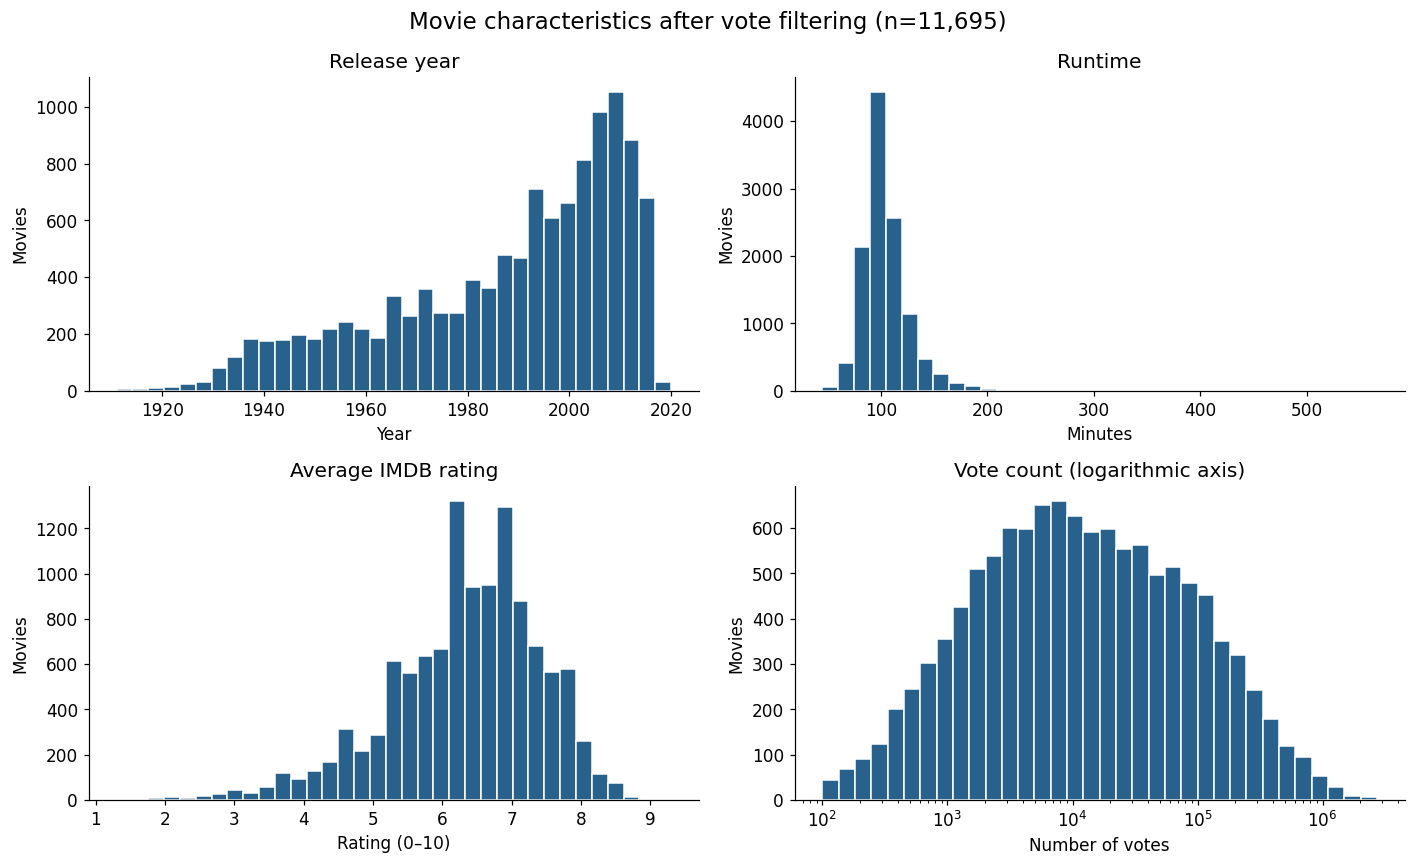

,startYear,runtimeMinutes,averageRating,numVotes
count,11695.00,11694.00,11695.00,11695.00
mean,1987.84,104.12,6.33,62854.53
std,23.06,23.04,1.09,153921.34
min,1911.00,45.00,1.30,100.00
25%,1973.00,90.00,5.70,2754.50
50%,1995.00,100.00,6.50,11140.00
75%,2007.00,113.00,7.10,52361.00
max,2020.00,566.00,9.30,2724626.00


**Observed interpretation.** Median rating is 6.5, median runtime is 100 minutes, and median votes are 11,140. The log vote axis preserves the long popularity tail without making most movies unreadable.

In [4]:
fig, axes = plt.subplots(2,2,figsize=(13,8))
for ax, col, title, xlabel in zip(axes.flat,
    ['startYear','runtimeMinutes','averageRating','numVotes'],
    ['Release year','Runtime','Average IMDB rating','Vote count (logarithmic axis)'],
    ['Year','Minutes','Rating (0–10)','Number of votes']):
    values = df[col].dropna()
    if col == 'numVotes':
        bins = np.geomspace(values.min(),values.max(),35)
        ax.hist(values,bins=bins,color=BLUE,edgecolor='white'); ax.set_xscale('log')
    else: ax.hist(values,bins=35,color=BLUE,edgecolor='white')
    ax.set(title=title,xlabel=xlabel,ylabel='Movies')
fig.suptitle(f'Movie characteristics after vote filtering (n={len(df):,})',fontsize=15)
fig.tight_layout(); plt.show()
display(df[['startYear','runtimeMinutes','averageRating','numVotes']].describe().round(2))
note(f'Median rating is {df.averageRating.median():.1f}, median runtime is '
     f'{df.runtimeMinutes.median():.0f} minutes, and median votes are {df.numVotes.median():,.0f}. '
     'The log vote axis preserves the long popularity tail without making most movies unreadable.')

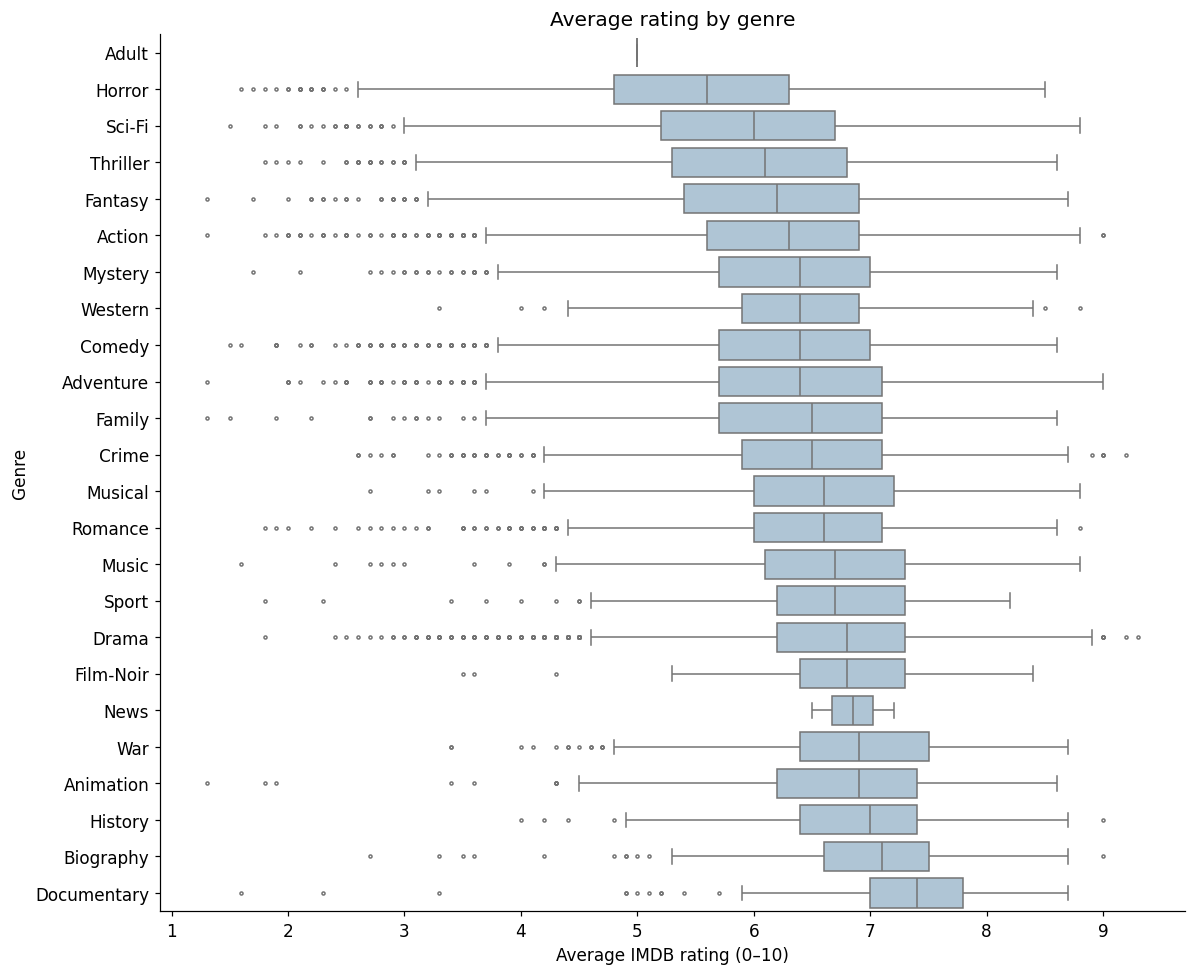

,count,median,mean
Genre,,,
Drama,6131,6.80,6.67
Comedy,3533,6.40,6.29
Action,2618,6.30,6.14
Crime,2501,6.50,6.49
Romance,2103,6.60,6.52
Horror,2079,5.60,5.53
Thriller,2027,6.10,6.03
Adventure,1805,6.40,6.30
Mystery,1302,6.40,6.26


In [5]:
rating_long = df.melt(id_vars=['imdb_id','averageRating'],value_vars=genre_columns,
                      var_name='Genre',value_name='Positive')
rating_long = rating_long.loc[rating_long.Positive.eq(1)]
rating_order = rating_long.groupby('Genre').averageRating.median().sort_values().index
fig, ax = plt.subplots(figsize=(11,9))
sns.boxplot(data=rating_long,x='averageRating',y='Genre',order=rating_order,
            color='#A8C6DC',fliersize=2,ax=ax)
ax.set(title='Average rating by genre',xlabel='Average IMDB rating (0–10)',ylabel='Genre')
fig.tight_layout(); plt.show()
rating_summary = rating_long.groupby('Genre').averageRating.agg(['count','median','mean'])
display(rating_summary.sort_values('count',ascending=False).round(2))

**Interpretation.** The 100-vote floor removes **79 train, 20 val and 30 test movies**, leaving **9,365 train + val** and **2,330 test**. Genres overlap, so a movie can appear in several rating boxes. Small genres have unstable summaries; these are descriptive associations, not evidence that genre causes rating. The same vote floor is fixed for the remaining notebooks.

## 2. Genre / class balance

**Decision.** Show every genre, including constant or very rare labels.

**Explanation.** Positive counts describe available examples; positive rates use all retained movies as the denominator. Because movies have multiple labels, rates are not a partition and do not sum to 100%. Use Pearson correlations of binary indicators to describe co-occurrence.

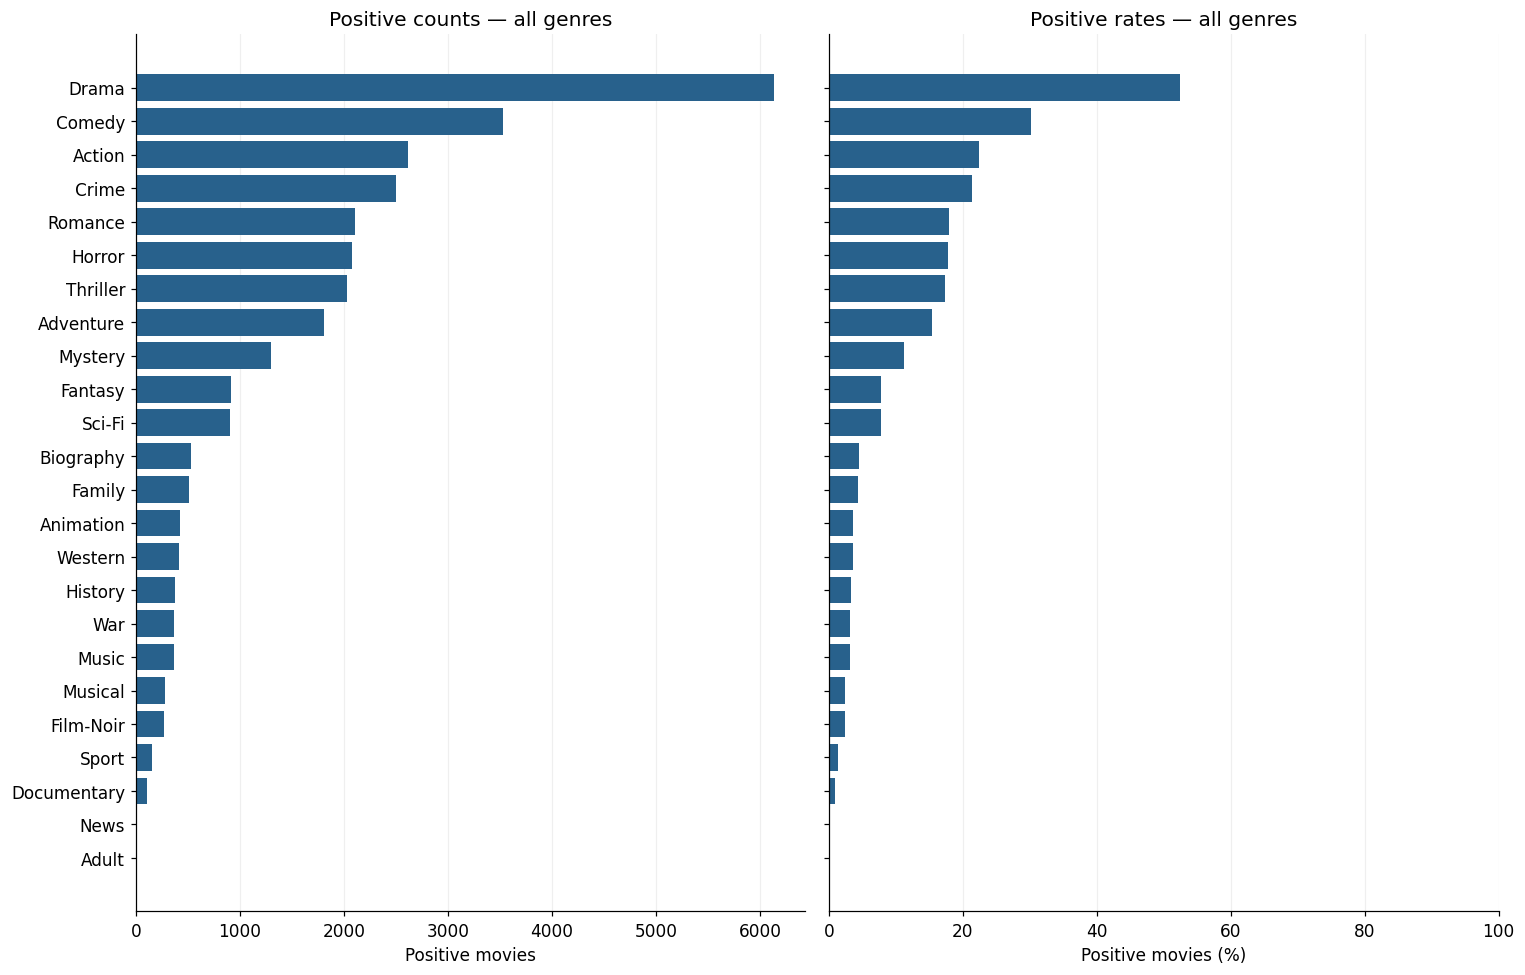

,positive_count,positive_pct
Drama,6131,52.42
Comedy,3533,30.21
Action,2618,22.39
Crime,2501,21.39
Romance,2103,17.98
Horror,2079,17.78
Thriller,2027,17.33
Adventure,1805,15.43
Mystery,1302,11.13
Fantasy,911,7.79


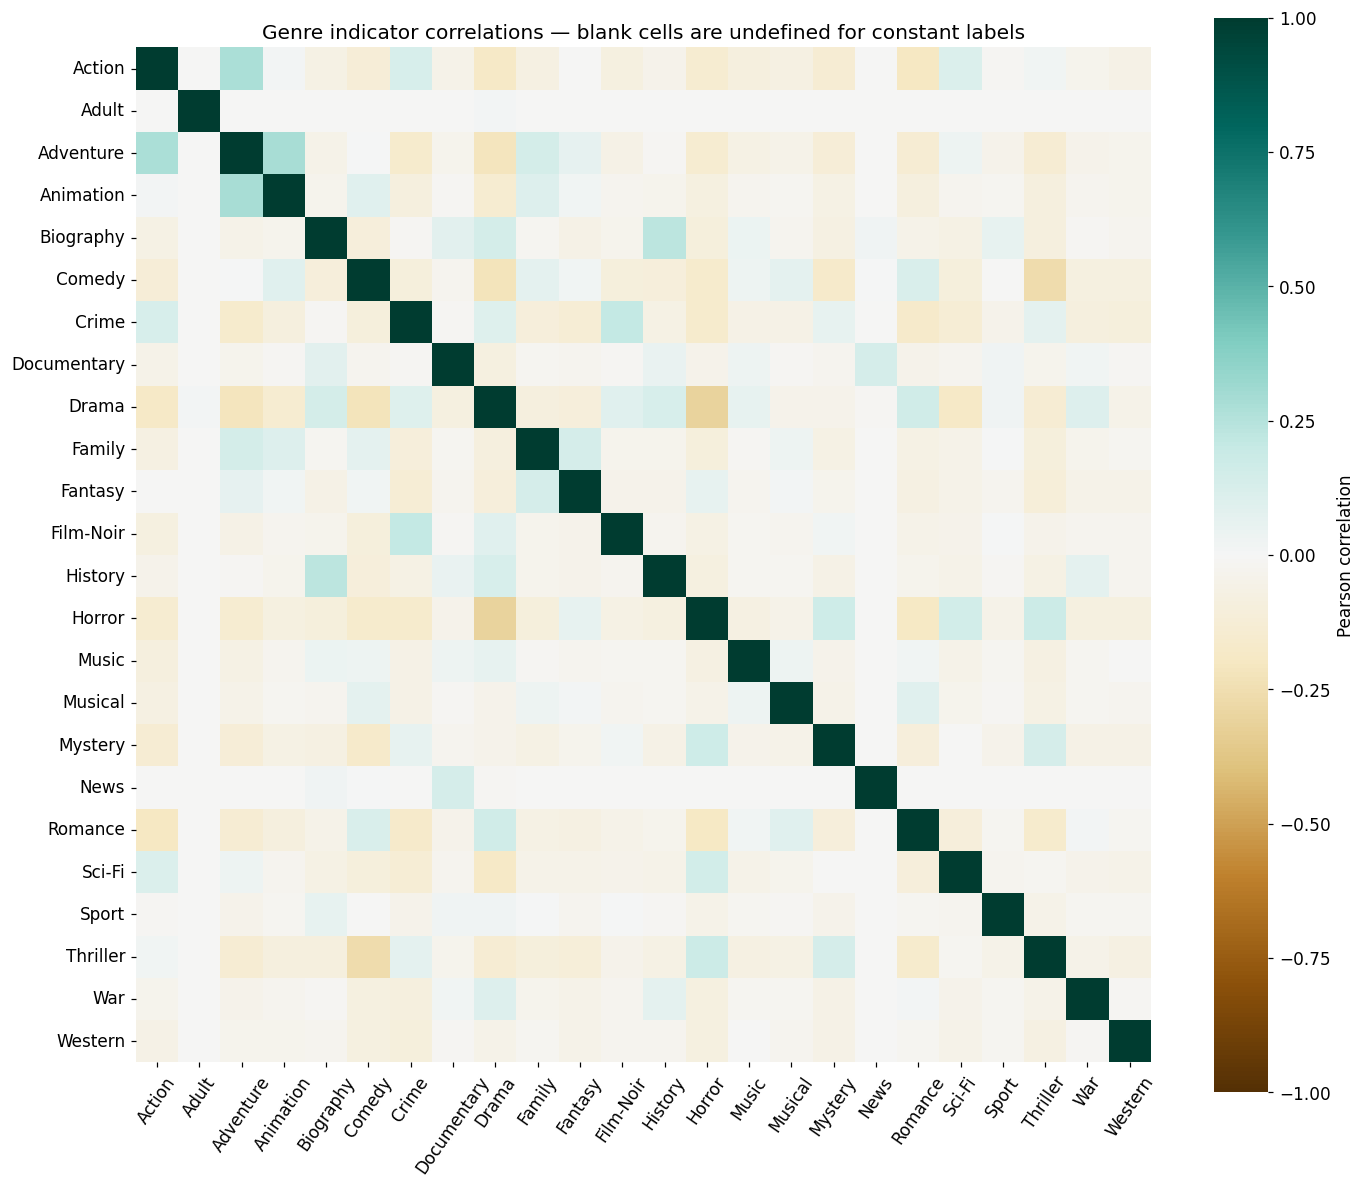

**Observed interpretation.** The largest genre is Drama (52.4%). Constant labels are []; their correlations are undefined, not zero. Co-occurrence supports treating each selected genre as an independent yes/no target.

In [7]:
balance = pd.DataFrame({'positive_count':df[genre_columns].sum(),
                         'positive_rate':df[genre_columns].mean()}).sort_values('positive_count')
fig, axes = plt.subplots(1,2,figsize=(14,9),sharey=True)
axes[0].barh(balance.index,balance.positive_count,color=BLUE)
axes[1].barh(balance.index,100*balance.positive_rate,color=BLUE)
axes[0].set(xlabel='Positive movies',title='Positive counts — all genres')
axes[1].set(xlabel='Positive movies (%)',title='Positive rates — all genres',xlim=(0,100))
for ax in axes: ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();plt.show()
display(balance.sort_values('positive_count',ascending=False).assign(
    positive_rate=lambda t:(100*t.positive_rate).round(2)).rename(columns={'positive_rate':'positive_pct'}))
corr = df[genre_columns].corr()
fig, ax = plt.subplots(figsize=(13,11))
sns.heatmap(corr,mask=corr.isna(),cmap='BrBG',center=0,vmin=-1,vmax=1,square=True,
            cbar_kws={'label':'Pearson correlation'},ax=ax)
ax.set_title('Genre indicator correlations — blank cells are undefined for constant labels')
ax.tick_params(axis='x',rotation=55);fig.tight_layout();plt.show()
constant_genres = [g for g in genre_columns if df[g].nunique()<2]
note(f'The largest genre is {balance.index[-1]} ({balance.iloc[-1].positive_rate:.1%}). '
     f'Constant labels are {constant_genres}; their correlations are undefined, not zero. '
     'Co-occurrence supports treating each selected genre as an independent yes/no target.')

**Interpretation.** Class weights will address imbalance in Notebook 2. No resampling is performed. Correlated genre targets remain separate labels; assigning exactly one genre would discard legitimate multi-label information.

## 3. Text characteristics and vocabulary

**Decision.** Use characters and whitespace-delimited words as approximate tokens; count words with regular expressions for EDA.

**Explanation.** These summaries do not fit a modeling vectorizer. Compare overall and genre-specific frequent terms, plus document-frequency enrichment. Genre vocabulary is descriptive, not a rule for selecting features using test labels.

,characters,approx_tokens
mean,5375.4,939.0
median,3914.0,675.0
min,560.0,101.0
max,63959.0,11406.0


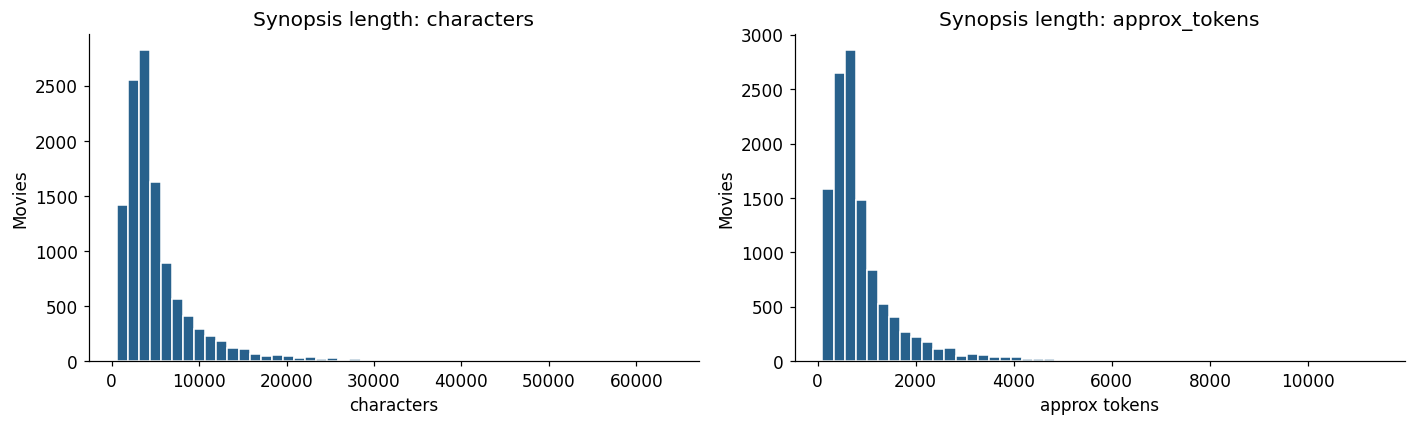

,Overall,Comedy,Horror,Action
1,tells,tells,tells,tells
2,man,time,house,man
3,says,new,room,men
4,house,home,man,car
5,goes,says,goes,takes
6,time,goes,finds,kill
7,home,man,car,time
8,asks,house,says,away
9,father,father,body,police
10,finds,asks,away,says


,Comedy,Horror,Action
1,nerdy,undead,ninja
2,comical,zombies,launcher
3,hilarious,dracula,mercenaries
4,comedy,paranormal,mercenary
5,cartoon,vampire,chopper
6,themed,zombie,kung
7,sexy,vampires,infiltrates
8,cheerleader,exorcism,bulletproof
9,prom,demonic,helicopters
10,pep,crypt,weaponry


**Observed interpretation.** Synopses have a median of 675 approximate tokens and a maximum of 11,406. 121 test movies (5.2%) repeat normalized training plot text. The mandated split is retained, but this overlap can inflate held-out performance.

,imdb_id,primaryTitle,startYear,Comedy,Horror,Action
165,tt0124901,Thursday,1998.0,1,0,1
175,tt0058777,Zulu,1964.0,0,0,0
191,tt0995039,Ghost Town,2008.0,1,0,0
223,tt1517260,The Host,2013.0,0,0,1
235,tt1139328,The Ghost Writer,2010.0,0,0,0
288,tt1334553,The Perfect Host,2010.0,1,0,0
315,tt1924429,Trance,2013.0,0,0,0
345,tt1024715,Choke,2008.0,1,0,0
355,tt0049674,Richard III,1955.0,0,0,0


**Observed interpretation.** 169 normalized plot groups have conflicting selected-genre targets, affecting 379 retained movies. A deterministic plot-only model cannot give different predictions to identical text. These rows require source-alignment review; no supplied labels are silently corrected or removed.

219

In [8]:
from collections import Counter
lengths = pd.DataFrame({'characters':df.plot_synopsis.str.len(),
                        'approx_tokens':df.plot_synopsis.str.split().str.len()})
display(lengths.agg(['mean','median','min','max']).round(1))
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,col in zip(axes,lengths.columns):
    ax.hist(lengths[col],bins=50,color=BLUE,edgecolor='white')
    ax.set(title=f'Synopsis length: {col}',xlabel=col.replace('_',' '),ylabel='Movies')
fig.tight_layout();plt.show()
def terms(text):
    return [w for w in re.findall(r"\b[a-z]{3,}\b",text.lower()) if w not in ENGLISH_STOP_WORDS]
all_counts=Counter()
genre_counts={g:Counter() for g in GENRES}
documents=[set(terms(t)) for t in df.plot_synopsis]
overall_df=Counter(w for doc in documents for w in doc)
for text in df.plot_synopsis:all_counts.update(terms(text))
for g in GENRES:
    for text in df.loc[df[g].eq(1),'plot_synopsis']:genre_counts[g].update(terms(text))
top_terms=pd.DataFrame({'Overall':[w for w,_ in all_counts.most_common(12)],
                        **{g:[w for w,_ in genre_counts[g].most_common(12)] for g in GENRES}})
display(top_terms.rename_axis('rank').set_axis(range(1,13)))
enrichment={}
for g in GENRES:
    selected_docs=[documents[i] for i in np.flatnonzero(df[g].to_numpy()==1)]
    gdf=Counter(w for doc in selected_docs for w in doc)
    # Ignore very sparse words; compare document rates, not raw corpus size.
    candidates=[w for w,c in gdf.items() if c>=30 and overall_df[w]>=50]
    scores={w:(gdf[w]/len(selected_docs))/(overall_df[w]/len(df)) for w in candidates}
    enrichment[g]=sorted(scores,key=scores.get,reverse=True)[:10]
display(pd.DataFrame(enrichment).rename_axis('rank').set_axis(range(1,11)))
train_text=normalized_text(df.loc[df.split.isin(['train','val']),'plot_synopsis'])
test_text=normalized_text(df.loc[df.split.eq('test'),'plot_synopsis'])
overlap_count=int(test_text.isin(set(train_text)).sum())
note(f'Synopses have a median of {lengths.approx_tokens.median():,.0f} approximate tokens '
     f'and a maximum of {lengths.approx_tokens.max():,}. '
     f'{overlap_count} test movies ({overlap_count/len(test_text):.1%}) repeat normalized training plot text. '
     'The mandated split is retained, but this overlap can inflate held-out performance.')

# Audit contradictory targets on identical normalized plot inputs without altering the supplied data.
plot_hashes=normalized_text(df.plot_synopsis).map(lambda text:hashlib.sha256(text.encode()).hexdigest())
plot_label_variation=df[GENRES].groupby(plot_hashes).nunique()
conflicting_hashes=set(plot_label_variation.index[plot_label_variation.gt(1).any(axis=1)])
affected=df.loc[plot_hashes.isin(conflicting_hashes)]
display(affected[['imdb_id','primaryTitle','startYear',*GENRES]].head(9))
note(f'{len(conflicting_hashes)} normalized plot groups have conflicting selected-genre targets, '
     f'affecting {len(affected)} retained movies. A deterministic plot-only model cannot give different '
     'predictions to identical text. These rows require source-alignment review; no supplied labels are silently corrected or removed.')

config={'team':TEAM,'min_votes':MIN_VOTES,'genres':GENRES,
        'fingerprint':frame_fingerprint(df),'overlapping_test_plots':overlap_count}
(WORK/'eda_config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')

**Interpretation.** Frequent terms often describe generic story structure or character names. Enrichment highlights words more characteristic of a genre, but does not demonstrate causality or guarantee generalization. Whitespace counts are approximate tokens, not the embedding or teacher model’s tokenization. Exact plot overlap limits claims about performance on entirely new stories. Identical plots attached to differing genre targets create ambiguity that model tuning cannot resolve; keep this separate from ordinary classification error.

### Handoff to Notebook 2
Use the same input file, vote floor and split. Notebook 2 combines `train` + `val` and holds `test` fixed. `eda_config.json` and the filter audit are written outside the repository. No feature vectorizer, scaler, classifier or model metric is produced here.